# Leitura rápida da escada — resultados já obtidos

100% local, 100% leitura de parquet: sem Colab, sem GPU, sem treino, sem SIR (o refit causal do
SIR é caro e fica pro `item10_comparacao_consolidada.ipynb`). Só monta tabelas e gráficos a
partir do que já está em `results/escada_treinos/` e `results/avaliacao_matriz/`.

Roda em segundos. Cobertura atual: 18/18 treinos (3 variantes × 2 regimes × 3 seeds).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.width", 160)
ROOT = Path.cwd()
if not (ROOT / "results").exists():
    ROOT = ROOT.parent
ESCADA = ROOT / "results" / "escada_treinos"
MATRIZ = ROOT / "results" / "avaliacao_matriz"
assert MATRIZ.exists(), f"não achei {MATRIZ} — rode a partir da raiz do repo ou de notebooks/"
print("lendo de", MATRIZ)

AssertionError: não achei /results/avaliacao_matriz — rode a partir da raiz do repo ou de notebooks/

## 1. Treino — val_mse por variante/regime/seed

In [ ]:
val_mse = pd.read_parquet(ESCADA / "matriz_val_mse.parquet")
display(val_mse.pivot_table(index=["regime", "seed"], columns="variante", values="val_mse"))

variante      embaralhado  proposta  sem_grafo
regime  seed                                  
current 42       0.000765  0.000752   0.000785
        43       0.000763  0.000755   0.000781

## 2. Modo 2 — RMSE por variante, nas 24 células (chart × k × recorte × regime)

Só o orçamento `completo` (a leitura principal; `teto_treino` é o controle do ticket 08, com uma
seed só). `n_seeds` mostra quantas sementes sustentam cada média.

In [ ]:
resumo = pd.read_parquet(MATRIZ / "resumo_mode2.parquet")
principal = resumo[resumo.orcamento_arestas == "completo"]

tabela = principal.pivot_table(
    index=["split_regime", "chart", "k", "recorte"],
    columns="variante", values="rmse_medio",
)[["proposta", "sem_grafo", "embaralhado"]]
display(tabela.round(5))

variante                        proposta  sem_grafo  embaralhado
split_regime chart   k recorte                                  
current      top200  1 full      0.02381    0.02374      0.02385
                       onchart   0.07707    0.07534      0.07685
                     2 full      0.03686    0.03682      0.03699
                       onchart   0.12112    0.11747      0.12040
                     4 full      0.05154    0.05137      0.05229
                       onchart   0.17547    0.16691      0.17598
             viral50 1 full      0.02593    0.02624      0.02573
                       onchart   0.16356    0.16453      0.16136
                     2 full      0.03409    0.03480      0.03394
                       onchart   0.21817    0.21861      0.21368
                     4 full      0.04463    0.04348      0.04470
                       onchart   0.28866    0.26839      0.28492
pre_pandemia top200  1 full      0.02868    0.02852      0.02914
                       onchart   0.07302    0.07207      0.07481
                     2 full      0.03956    0.03971      0.04035
                       onchart   0.09632    0.09616      0.10005
                     4 full      0.05369    0.05313      0.05424
                       onchart   0.13533    0.13443      0.14073
             viral50 1 full      0.03132    0.03144      0.03121
                       onchart   0.15158    0.15287      0.15325
                     2 full      0.04153    0.04129      0.04160
                       onchart   0.20853    0.20934      0.21166
                     4 full      0.05232    0.05182      0.05371
                       onchart   0.24568    0.24920      0.25524

## 3. O quase-empate, em %

Diferença relativa da proposta contra cada controle. Valores pequenos (a maioria abaixo de 3%)
são o que sustenta o desfecho condicional do ADR-0001 — mas isto ainda é RMSE bruto, não teste
estatístico (isso é o item 10).

In [ ]:
diff = tabela.copy()
diff["proposta_vs_sem_grafo_%"] = (tabela.proposta - tabela.sem_grafo) / tabela.sem_grafo * 100
diff["proposta_vs_embaralhado_%"] = (tabela.proposta - tabela.embaralhado) / tabela.embaralhado * 100
display(diff[["proposta_vs_sem_grafo_%", "proposta_vs_embaralhado_%"]].round(2))

maior_abs = diff[["proposta_vs_sem_grafo_%", "proposta_vs_embaralhado_%"]].abs().max().max()
print(f"\nmaior |diferença| observada entre as 3 variantes: {maior_abs:.1f}%")

variante                        proposta_vs_sem_grafo_%  proposta_vs_embaralhado_%
split_regime chart   k recorte                                                    
current      top200  1 full                        0.31                      -0.17
                       onchart                     2.29                       0.28
                     2 full                        0.12                      -0.34
                       onchart                     3.11                       0.60
                     4 full                        0.33                      -1.45
                       onchart                     5.13                      -0.29
             viral50 1 full                       -1.17                       0.76
                       onchart                    -0.59                       1.37
                     2 full                       -2.03                       0.46
                       onchart                    -0.20                       2.10
                     4 full                        2.64                      -0.17
                       onchart                     7.55                       1.31
pre_pandemia top200  1 full                        0.59                      -1.58
                       onchart                     1.33                      -2.38
                     2 full                       -0.38                      -1.95
                       onchart                     0.17                      -3.72
                     4 full                        1.05                      -1.02
                       onchart                     0.67                      -3.84
             viral50 1 full                       -0.38                       0.37
                       onchart                    -0.85                      -1.09
                     2 full                        0.57                      -0.17
                       onchart                    -0.39                      -1.48
                     4 full                        0.97                      -2.58
                       onchart                    -1.41                      -3.75


maior |diferença| observada entre as 3 variantes: 7.5%


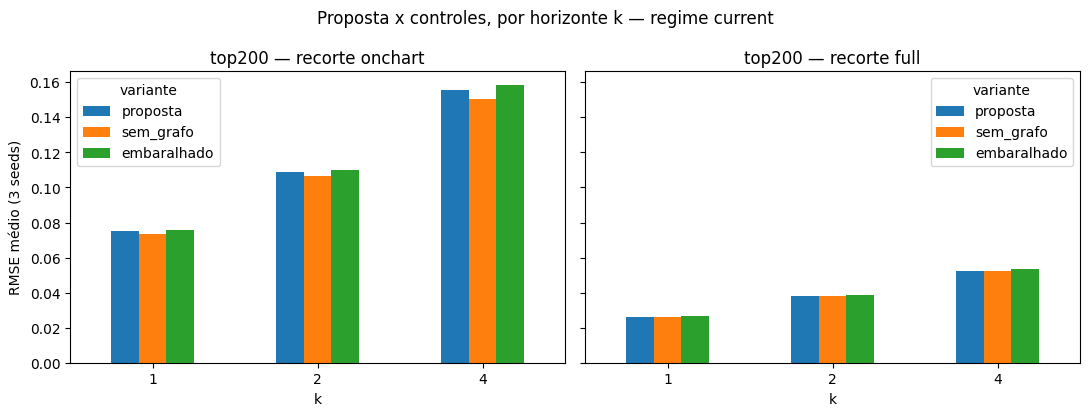

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, recorte in zip(axes, ["onchart", "full"]):
    sub = (principal[(principal.recorte == recorte) & (principal.chart == "top200")]
           .pivot_table(index="k", columns="variante", values="rmse_medio"))
    sub[["proposta", "sem_grafo", "embaralhado"]].plot.bar(ax=ax, rot=0)
    ax.set_title(f"top200 — recorte {recorte}")
    ax.set_ylabel("RMSE médio (3 seeds)")
fig.suptitle("Proposta x controles, por horizonte k — regime current")
fig.tight_layout()
plt.show()

## 4. Ablação por tipo de aresta e por grupo de features

`delta_rmse` positivo = remover piora o modelo (a relação carregava sinal útil). Negativo = tanto
faz, ou até ajuda remover.

In [ ]:
abl = pd.read_parquet(MATRIZ / "ablacao_agregada.parquet")
abl_onchart = abl[(abl.recorte == "onchart") & (abl.chart == "ambos")]
display(abl_onchart.pivot_table(index="componente", columns="split_regime",
                                 values="delta_rmse_medio").sort_values("current", ascending=False)
        .round(5))

split_regime,current,pre_pandemia
componente,,
sem_cotrajectory[music->music],0.06884,0.04470
acustica,0.00292,0.00295
sem_cooccurs[genre->genre],0.00007,0.00020
metadados,0.00002,0.00009
sem_has_genre[artist->genre],-0.00040,-0.00045
sem_rev_has_genre[genre->artist],-0.00145,-0.00145
sem_performs[artist->music],-0.00276,-0.00135


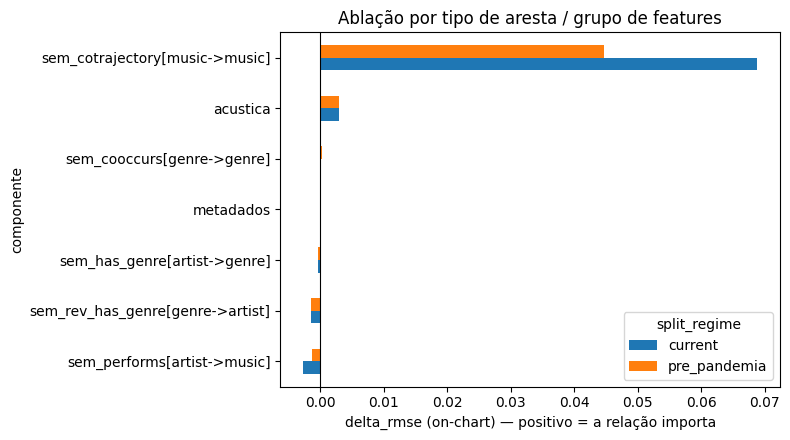

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
piv = abl_onchart.pivot_table(index="componente", columns="split_regime", values="delta_rmse_medio")
piv = piv.sort_values("current", ascending=True)
piv.plot.barh(ax=ax)
ax.axvline(0, color="black", linewidth=.8)
ax.set_xlabel("delta_rmse (on-chart) — positivo = a relação importa")
ax.set_title("Ablação por tipo de aresta / grupo de features")
fig.tight_layout()
plt.show()

## 5. Resumo pra colar no capítulo

Texto gerado a partir dos números acima — conferir antes de usar.

In [ ]:
cotraj = abl_onchart[abl_onchart.componente.str.contains("cotrajectory")]
print("Achados desta leitura (RMSE bruto, sem teste estatístico ainda):\n")
print(f"- proposta, sem_grafo e embaralhado ficam a no máximo {maior_abs:.1f}% uma da outra "
      f"no Modo 2, nas 24 células (chart×k×recorte×regime).")
for _, r in cotraj.iterrows():
    print(f"- remover cotrajectory piora o RMSE on-chart em {r.delta_rmse_medio:+.4f} "
          f"no regime {r.split_regime} — segue sendo a única relação com efeito grande.")
print("\nPendente: item10_comparacao_consolidada.ipynb (SIR/persistência + Wilcoxon+Holm+bootstrap) "
      "decide se o quase-empate é estatisticamente real.")

Achados desta leitura (RMSE bruto, sem teste estatístico ainda):

- proposta, sem_grafo e embaralhado ficam a no máximo 7.5% uma da outra no Modo 2, nas 24 células (chart×k×recorte×regime).
- remover cotrajectory piora o RMSE on-chart em +0.0688 no regime current — segue sendo a única relação com efeito grande.
- remover cotrajectory piora o RMSE on-chart em +0.0447 no regime pre_pandemia — segue sendo a única relação com efeito grande.

Pendente: item10_comparacao_consolidada.ipynb (SIR/persistência + Wilcoxon+Holm+bootstrap) decide se o quase-empate é estatisticamente real.
